# Ансамблевая регрессия: VotingClassifier

## 1. Импорт библиотек

In [126]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                           f1_score, roc_auc_score, classification_report,
                           roc_curve, confusion_matrix)



from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

## 2. Загрузка, предобработка данных и разделение на train/test

In [127]:
df = pd.read_csv('framingham (2).csv')

In [128]:
df

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0


Проверим данные на наличие пропущенных значений 

In [129]:
missing_counts = df.isnull().sum()
print(missing_counts)

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64


Так как пропущенные значения составляют более 5% данных, заполним пропуски с помощью медианы.

In [130]:
df_clean = df.fillna(df.median())

In [131]:
df_clean

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,0.0,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,78.0,0


In [132]:
missing_counts = df_clean.isnull().sum()
print(missing_counts)

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64


Сократим размерность данных до 500 наблюдений, выберем случайные 500 наблюдений:

In [133]:
# df_clean = df_clean.sample(n = 2000, random_state = 667)

In [134]:
#df_clean 

Разделим данные на целевую переменную и признаки 

In [135]:
X = df_clean.drop('TenYearCHD', axis=1)
y = df_clean['TenYearCHD']

In [136]:
X

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0
4235,0,48,2.0,1,20.0,0.0,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,78.0


In [137]:
y

0       0
1       0
2       0
3       1
4       0
       ..
4233    1
4234    0
4235    0
4236    0
4237    0
Name: TenYearCHD, Length: 4238, dtype: int64

In [138]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [139]:
# разделяем на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)

## 3. Создание и обучение отдельных моделей классификации

In [140]:
# создаём три разные модели

clas_gb = GradientBoostingClassifier(random_state=1)
clas_rf = RandomForestClassifier(random_state=1)
clas_svc = SVC(random_state=1)
clas_dt = DecisionTreeClassifier(random_state=1)

In [141]:
# обучаем каждую модель на обучающей выборке

In [142]:
clas_gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [143]:
clas_rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [144]:
clas_svc.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [145]:
clas_dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


## 4. Создание и обучение VotingClassifier

In [146]:
# создаём ансамбль, который усредняет предсказания трёх моделей
voting_clas = VotingClassifier(
    estimators=[
        ("gb", clas_gb),
        ("rf", clas_rf),
        ("svc", clas_svc),
        ("dt", clas_dt)
        
    ]
)

# обучаем ансамбль
voting_clas.fit(X_train, y_train)

,estimators,"[('gb', ...), ('rf', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'


## 5. Оценка качества моделей на тестовой выборке

In [172]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, r2_score

# предсказания на тестовых данных
y_pred_gb = clas_gb.predict(X_test)
y_pred_rf = clas_rf.predict(X_test)
y_pred_svc = clas_svc.predict(X_test)
y_pred_dt = clas_dt.predict(X_test)
y_pred_voting = voting_clas.predict(X_test)

def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    r2 = r2_score(y_true, y_pred)
    
    print(f"{name:25s}")
    print(f"  MSE      = {mse:8.4f}")
    print(f"  R²       = {r2:8.4f}")
    print(f"  Accuracy = {accuracy:8.4f}")
    print(f"  Precision= {precision:8.4f}")
    print(f"  Recall   = {recall:8.4f}")
    print(f"  F1-score = {f1:8.4f}")
    print("-" * 40)
evaluate_model("GradientBoosting", y_test, y_pred_gb)
evaluate_model("RandomForest", y_test, y_pred_rf)
evaluate_model("SVC", y_test, y_pred_svc)
evaluate_model("DecisionTree", y_test, y_pred_dt)
evaluate_model("Voting", y_test, y_pred_voting)  

GradientBoosting         
  MSE      =   0.1557
  R²       =  -0.2468
  Accuracy =   0.8443
  Precision=   0.3667
  Recall   =   0.0887
  F1-score =   0.1429
----------------------------------------
RandomForest             
  MSE      =   0.1415
  R²       =  -0.1335
  Accuracy =   0.8585
  Precision=   0.6111
  Recall   =   0.0887
  F1-score =   0.1549
----------------------------------------
SVC                      
  MSE      =   0.1486
  R²       =  -0.1902
  Accuracy =   0.8514
  Precision=   0.0000
  Recall   =   0.0000
  F1-score =   0.0000
----------------------------------------
DecisionTree             
  MSE      =   0.2241
  R²       =  -0.7947
  Accuracy =   0.7759
  Precision=   0.2537
  Recall   =   0.2742
  F1-score =   0.2636
----------------------------------------
Voting                   
  MSE      =   0.1415
  R²       =  -0.1335
  Accuracy =   0.8585
  Precision=   0.6667
  Recall   =   0.0645
  F1-score =   0.1176
----------------------------------------


* Для каждой модели считаем:

  * `MSE` — среднеквадратичная ошибка: чем меньше, тем лучше.
  * `R²` — коэффициент детерминации:

    * ближе к 1 → модель хорошо объясняет вариацию целевой переменной;
    * около 0 → не лучше константного предсказания (среднее по y);
    * может быть отрицательным, если модель совсем плоха.
* Сравнивая строки вывода, можно понять, даёт ли ансамбль выигрыш по качеству.




## 6. Визуализация предсказаний для первых 20 объектов тестовой выборки

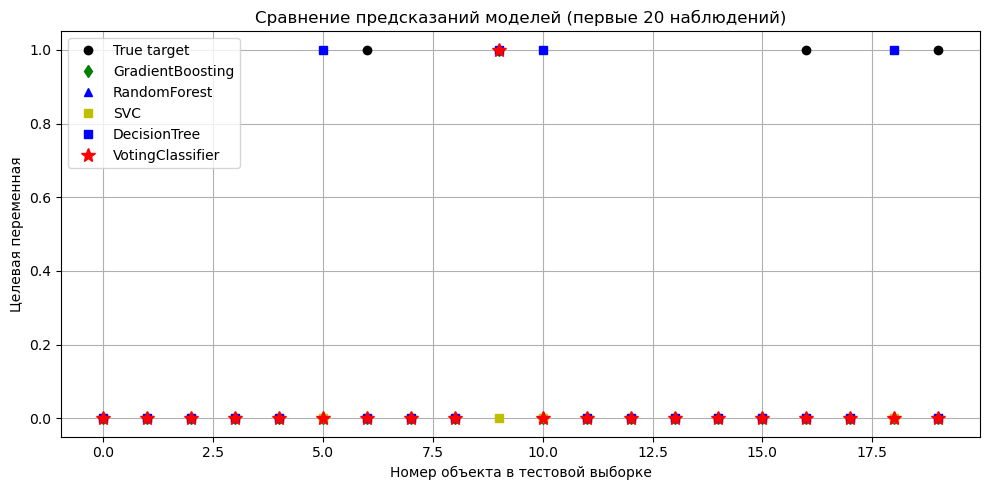

In [121]:
# выберем первые 20 объектов из тестовой выборки

n_samples = 20
xt = X_test[:n_samples]
yt_true = y_test[:n_samples]

# предсказания для этих же 20 объектов
pred_gb = clas_gb.predict(xt)
pred_rf = clas_rf.predict(xt)
pred_svc = clas_svc.predict(xt)
pred_dt = clas_dt.predict(xt)
pred_voting = voting_clas.predict(xt)

plt.figure(figsize=(10, 5))

indices = np.arange(n_samples)

# истинные значения
plt.plot(indices, yt_true, "ko", label="True target")

# предсказания отдельных моделей
plt.plot(indices, pred_gb, "gd", label="GradientBoosting")
plt.plot(indices, pred_rf, "b^", label="RandomForest")
plt.plot(indices, pred_svc, "ys", label="SVC")
plt.plot(indices, pred_dt, "bs", label="DecisionTree")

# предсказания ансамбля
plt.plot(indices, pred_voting, "r*", ms=10, label="VotingClassifier")
plt.xlabel("Номер объекта в тестовой выборке")
plt.ylabel("Целевая переменная")
plt.title("Сравнение предсказаний моделей (первые 20 наблюдений)")
plt.legend(loc="best")
plt.grid(True)
plt.tight_layout()
plt.show()

Вывод: с помощью VotingClassifier была получена усредненная модель, которая совпала с наилучшей моделью из имеющихся полученных - модель RandomForest.
Данная модель имеет наименьшую среднеквадратическую ошибку и наиближайщее к 1 значение коэффициента детерминации. При этом все полученные модели для выбранных данных являются не оптимальными и недостаточно точными на основе коэффициента детерминации, даже наилучшая выбранная модель имеет отрицательный коэффициент. При этом по метрике Accuracy наилучшая модель достаточно точна 0.8585.